# Paso 5 – Clustering **versión 2**: perfil situacional sin edad ni sexo (Gower)

**Dataset:** `Resultados_EnfoqueB/Dataset_final_enfoqueB.xlsx` (Paso 4B), las mismas 161 NNA que la versión 1.

**Idea de esta versión:** el documento de referencia pide contrastar la inclusión de **edad y sexo**. En la v1 el sexo dividía a los grupos casi por la mitad, y como los hogares están separados por sexo, en la práctica eso reproducía el hogar, que el documento pide **no** usar para modelar. Esta versión deja **11 variables situacionales**: legal (situación jurídica, permanencia), administrativa (estado e historial del PTI), educativa (rezago), nutricional (score de IMC y malnutrición), salud y psicoemocional (nivel de atención, salud física, discapacidad) y procedencia. La **edad, el sexo y el hogar se usan solo para describir** los perfiles.

**Modelos:** AGNES, PAM/K-Medoids, K-Prototypes y HDBSCAN, los mismos que la v1 y con los mismos criterios, para que la comparación sea directa.

# 1. Librerías y lectura del dataset de la versión

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster, cophenet, dendrogram
from scipy.spatial.distance import squareform
from scipy.stats import chi2_contingency
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.cluster import HDBSCAN
from sklearn.manifold import MDS
from kmodes.kprototypes import KPrototypes

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)

VERSION = 'v2'
BASE = Path.cwd().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
RUTA = BASE / 'Resultados_EnfoqueB'
X = pd.read_excel(RUTA / 'Dataset_final_enfoqueB.xlsx', sheet_name='dataset').set_index('id_persona')
versiones = pd.read_excel(RUTA / 'Dataset_final_enfoqueB.xlsx', sheet_name='versiones')
TIPOS = dict(versiones.loc[versiones['version'] == VERSION, ['variable', 'tipo_gower']].values)
VARS = list(TIPOS)
N = len(X)
print(f'Versión {VERSION}: {N} NNA | {len(VARS)} variables')
pd.DataFrame({'tipo': TIPOS, 'vacíos': X[VARS].isna().sum(), 'valores distintos': X[VARS].nunique()})

Versión v2: 161 NNA | 11 variables


,tipo,vacíos,valores distintos
ln_permanencia,num,0,103
procedencia_provincias,bin,0,2
salud_fisica_cronica,bin,0,2
presenta_discapacidad,bin,0,2
nivel_atencion_salud_mental,ord,0,4
flag_rezago_escolar,bin,0,2
estado_pti,cat,0,4
situacion_juridica,cat,0,4
score_imc,ord,0,6
malnutricion_flag,bin,0,2


**Tipos para Gower:** `num` (numérica, normalizada por su rango), `ord` (ordinal, tratada como numérica normalizada para que la distancia entre niveles extremos sea mayor), `cat` y `bin` (coincidencia simple: 0 si son iguales, 1 si difieren). Las binarias se tratan de forma **simétrica**, es decir, que dos NNA coincidan en 0 (por ejemplo, ambas sin discapacidad) también cuenta como parecido, porque en este caso la ausencia de la condición también es informativa.

# 2. Matriz de distancias de Gower

Diferencia máxima con la librería gower: 3.17e-08
Distancias: media = 0.325 | mediana = 0.319 | mín = 0.000 | máx = 0.855


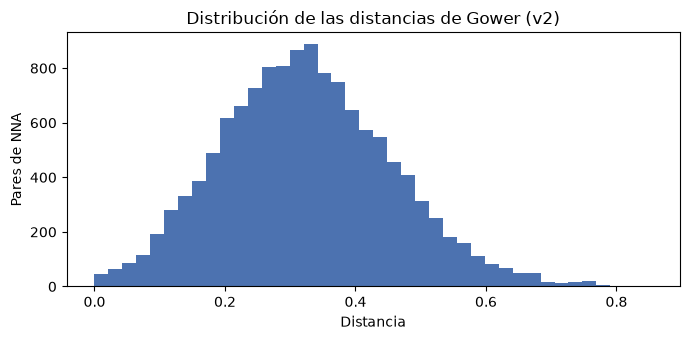

In [2]:
def gower(df, tipos):
    """Distancia de Gower. Numéricas/ordinales: |x - y| / rango. Categóricas/binarias: 0 si coinciden, 1 si no.
    Los vacíos se excluyen par a par (la distancia promedia solo las variables disponibles)."""
    n = len(df)
    num, den = np.zeros((n, n)), np.zeros((n, n))
    for c, t in tipos.items():
        x = df[c]
        ok = np.asarray(x.notna())
        valid = ok[:, None] & ok[None, :]
        if t in ('num', 'ord'):
            v = np.asarray(x, dtype=float)
            rango = np.nanmax(v) - np.nanmin(v)
            d = np.abs(v[:, None] - v[None, :]) / rango if rango > 0 else np.zeros((n, n))
        else:
            v = np.asarray(x.astype(str), dtype=object)
            d = (v[:, None] != v[None, :]).astype(float)
        num += np.where(valid, d, 0)
        den += valid
    D = num / den
    np.fill_diagonal(D, 0)
    return D


D = gower(X, TIPOS)

# Validación con la librería `gower` usada en clase (si está instalada)
try:
    import gower as gower_lib
    Xg = X[VARS].copy()
    for c in VARS:
        Xg[c] = Xg[c].astype(object) if TIPOS[c] == 'cat' else Xg[c].astype(float)
    Dlib = gower_lib.gower_matrix(Xg, cat_features=[TIPOS[c] == 'cat' for c in VARS])
    print(f'Diferencia máxima con la librería gower: {np.abs(D - Dlib).max():.2e}')
except Exception as e:
    print('No se pudo comparar con la librería gower:', e)

iu = np.triu_indices(N, 1)
print(f'Distancias: media = {D[iu].mean():.3f} | mediana = {np.median(D[iu]):.3f} | mín = {D[iu].min():.3f} | máx = {D[iu].max():.3f}')
plt.figure(figsize=(7, 3.5))
plt.hist(D[iu], bins=40, color='#4c72b0')
plt.title(f'Distribución de las distancias de Gower ({VERSION})')
plt.xlabel('Distancia')
plt.ylabel('Pares de NNA')
plt.tight_layout()
plt.show()

# 3. Funciones comunes: PAM, métricas, estabilidad y criterio de selección

- **PAM** (*Partitioning Around Medoids*) se implementa directamente (fases BUILD y SWAP), porque `scikit-learn-extra` no se instala en las versiones recientes de Python. El medoide es una NNA real que representa a su grupo.
- **Métricas internas** (todas sobre la misma matriz de Gower, para que los modelos sean comparables):
  - **Silueta** (de −1 a 1): cohesión frente a separación de cada NNA.
  - **Cohesión:** distancia media entre NNA del mismo cluster (menor es mejor).
  - **Separación:** distancia media entre NNA de clusters distintos (mayor es mejor).
  - **Dunn:** menor distancia entre clusters dividida por el mayor diámetro (mayor es mejor).
- **Estabilidad:** se remuestrea el 80 % de las NNA sin reemplazo, se vuelve a agrupar y se compara con la partición completa mediante el **ARI** (*Adjusted Rand Index*). Un ARI medio ≥ 0.75 indica una partición estable.
- **Criterio de selección de k:** el objetivo es obtener perfiles para revisiones interdisciplinarias, así que se buscan **entre 3 y 7 grupos** (2 es demasiado general y más de 7 fragmenta 161 NNA en grupos muy chicos), con un **mínimo de 8 NNA por grupo** (5 %). Entre los candidatos se elige el que maximiza el **índice combinado = silueta × ARI medio**, que premia a la vez la separación y la estabilidad.

In [3]:
def pam(D, k, max_iter=50):
    n = len(D)
    med = [int(np.argmin(D.sum(1)))]                     # BUILD: primer medoide = el más central
    for _ in range(1, k):
        dmin = D[:, med].min(1)
        ganancia = np.array([np.maximum(dmin - D[:, j], 0).sum() if j not in med else -1 for j in range(n)])
        med.append(int(np.argmax(ganancia)))
    costo = D[:, med].min(1).sum()
    for _ in range(max_iter):                            # SWAP: intercambia medoide por no medoide si baja el costo
        mejoro = False
        for i in range(k):
            for h in range(n):
                if h in med:
                    continue
                m = med.copy()
                m[i] = h
                c = D[:, m].min(1).sum()
                if c < costo - 1e-12:
                    costo, med, mejoro = c, m, True
        if not mejoro:
            break
    return np.array(med), D[:, med].argmin(1), costo


def metricas(D, lab):
    lab = np.asarray(lab)
    ks = np.unique(lab)
    mismo = lab[:, None] == lab[None, :]
    off = ~np.eye(len(D), dtype=bool)
    diam = max(D[np.ix_(lab == a, lab == a)].max() for a in ks)
    min_inter = min(D[np.ix_(lab == a, lab == b)].min() for i, a in enumerate(ks) for b in ks[i + 1:])
    return {'k': len(ks), 'silueta': silhouette_score(D, lab, metric='precomputed'),
            'cohesion_intra': D[mismo & off].mean(), 'separacion_inter': D[~mismo].mean(),
            'dunn': min_inter / diam, 'tamano_min': int(np.bincount(pd.factorize(lab)[0]).min())}


def estabilidad(ajustar, D, k, B=100, frac=0.8, semilla=0):
    """ARI medio entre la partición completa y las particiones de submuestras del 80 %."""
    rng = np.random.default_rng(semilla)
    completa = ajustar(D, k, np.arange(len(D)))
    aris = []
    for _ in range(B):
        idx = np.sort(rng.choice(len(D), int(frac * len(D)), replace=False))
        aris.append(adjusted_rand_score(completa[idx], ajustar(D[np.ix_(idx, idx)], k, idx)))
    return np.mean(aris), np.std(aris)


K_RANGO = range(2, 9)
K_CANDIDATOS = range(3, 8)
TAM_MIN = 8


def tabla_k(nombre, ajustar, B=100):
    filas = []
    for k in K_RANGO:
        lab = ajustar(D, k, np.arange(N))
        m = metricas(D, lab)
        m['ARI_medio'], m['ARI_sd'] = estabilidad(ajustar, D, k, B=B)
        filas.append(m)
    t = pd.DataFrame(filas).set_index('k')
    t['indice_combinado'] = t['silueta'] * t['ARI_medio']
    t['candidato'] = t.index.isin(K_CANDIDATOS) & (t['tamano_min'] >= TAM_MIN)
    t.insert(0, 'modelo', nombre)
    return t


def elegir_k(t):
    return int(t[t['candidato']]['indice_combinado'].idxmax())


def cramer_v(a, b):
    t = pd.crosstab(np.asarray(a), np.asarray(b))
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))


def eta2(cat, num):
    d = pd.DataFrame({'c': np.asarray(cat), 'n': np.asarray(num, dtype=float)}).dropna()
    m = d['n'].mean()
    return d.groupby('c')['n'].apply(lambda s: len(s) * (s.mean() - m) ** 2).sum() / ((d['n'] - m) ** 2).sum()

# 4. Modelo 1 – AGNES (jerárquico aglomerativo) sobre Gower

El método de Ward supone distancias euclidianas, así que no corresponde con Gower. Se comparan los enlaces que sí aceptan cualquier disimilitud (promedio, completo, simple y ponderado) mediante la **correlación cofenética**, que mide qué tan bien el dendrograma conserva las distancias originales.

Correlación cofenética:

 {'average': np.float64(0.674), 'complete': np.float64(0.544), 'single': np.float64(0.58), 'weighted': np.float64(0.598)}


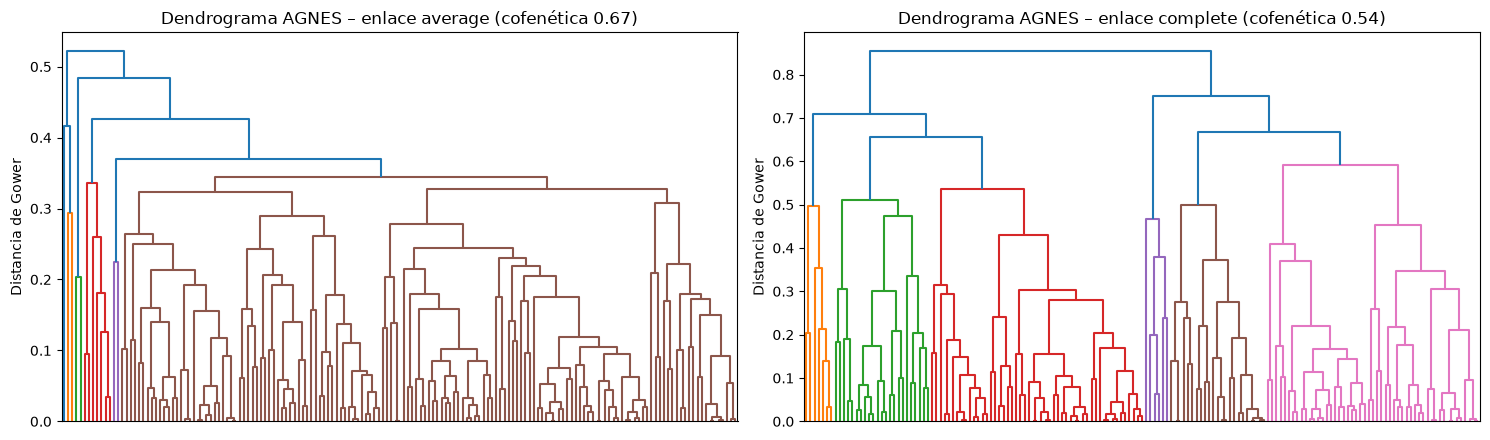

,modelo,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,ARI_sd,indice_combinado,candidato
k,,,,,,,,,,
2,AGNES promedio,0.372,0.317,0.522,0.223,3,0.682,0.341,0.254,False
3,AGNES promedio,0.289,0.313,0.507,0.214,2,0.621,0.235,0.179,False
4,AGNES promedio,0.214,0.302,0.461,0.119,2,0.701,0.193,0.150,False
5,AGNES promedio,0.182,0.302,0.461,0.119,1,0.641,0.205,0.116,False
6,AGNES promedio,0.112,0.300,0.448,0.119,1,0.509,0.231,0.057,False
7,AGNES promedio,0.190,0.257,0.375,0.133,1,0.284,0.250,0.054,False
8,AGNES promedio,0.166,0.257,0.375,0.133,1,0.272,0.235,0.045,False
2,AGNES completo,0.251,0.278,0.371,0.123,80,0.158,0.226,0.040,False
3,AGNES completo,0.222,0.272,0.370,0.131,6,0.247,0.239,0.055,False


In [4]:
Dc = squareform(D, checks=False)
cofe = {m: cophenet(linkage(Dc, m), Dc)[0] for m in ['average', 'complete', 'single', 'weighted']}
print('Correlación cofenética:', {m: round(v, 3) for m, v in cofe.items()})

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, m in zip(ax, ['average', 'complete']):
    dendrogram(linkage(Dc, m), ax=a, no_labels=True, color_threshold=None)
    a.set_title(f'Dendrograma AGNES – enlace {m} (cofenética {cofe[m]:.2f})')
    a.set_ylabel('Distancia de Gower')
plt.tight_layout()
plt.show()


def ajustar_agnes(metodo):
    return lambda Dm, k, idx: fcluster(linkage(squareform(Dm, checks=False), metodo), k, 'maxclust')


t_avg = tabla_k('AGNES promedio', ajustar_agnes('average'))
t_com = tabla_k('AGNES completo', ajustar_agnes('complete'))
pd.concat([t_avg, t_com]).round(3)

In [5]:
print('Tamaños de los grupos, enlace promedio:', {k: np.bincount(ajustar_agnes('average')(D, k, None))[1:].tolist() for k in (3, 4, 5)})

Tamaños de los grupos, enlace promedio: {3: [3, 2, 156], 4: [3, 2, 7, 149], 5: [2, 1, 2, 7, 149]}


**Comentario 4:** **AGNES tampoco produce una partición útil en la v2.**
- El enlace **promedio** (cofenética 0.67) vuelve a aislar atípicos: grupos de 2 o 3 NNA frente a uno de más de 150.
- El enlace **completo** mantiene en todos los k un grupo de 6 o 7 NNA (menos del mínimo de 8) y es inestable (ARI de 0.16 a 0.51).

Ningún k de AGNES es candidato.

# 5. Modelo 2 – PAM / K-Medoids sobre Gower

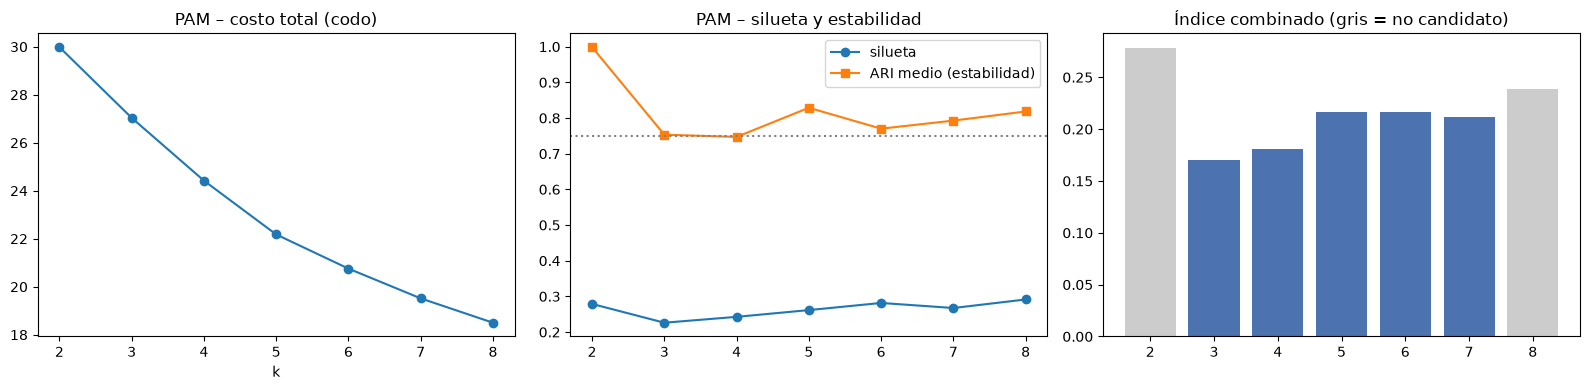

,modelo,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,ARI_sd,indice_combinado,candidato,costo
k,,,,,,,,,,,
2,PAM,0.279,0.274,0.376,0.123,72,0.999,0.012,0.278,False,29.985
3,PAM,0.226,0.254,0.361,0.040,41,0.753,0.248,0.170,True,27.038
4,PAM,0.243,0.233,0.357,0.107,26,0.747,0.221,0.181,True,24.421
5,PAM,0.262,0.217,0.354,0.047,22,0.829,0.152,0.217,True,22.179
6,PAM,0.282,0.197,0.353,0.036,13,0.770,0.130,0.217,True,20.755
7,PAM,0.267,0.192,0.346,0.032,19,0.793,0.106,0.212,True,19.515
8,PAM,0.291,0.182,0.345,0.055,14,0.818,0.090,0.238,False,18.501


In [6]:
ajustar_pam = lambda Dm, k, idx: pam(Dm, k)[1]
t_pam = tabla_k('PAM', ajustar_pam)
costos = {k: pam(D, k)[2] for k in K_RANGO}
t_pam['costo'] = pd.Series(costos)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(list(costos), list(costos.values()), marker='o')
ax[0].set_title('PAM – costo total (codo)')
ax[0].set_xlabel('k')
ax[1].plot(t_pam.index, t_pam['silueta'], marker='o', label='silueta')
ax[1].plot(t_pam.index, t_pam['ARI_medio'], marker='s', label='ARI medio (estabilidad)')
ax[1].axhline(0.75, color='gray', ls=':')
ax[1].set_title('PAM – silueta y estabilidad')
ax[1].legend()
ax[2].bar(t_pam.index, t_pam['indice_combinado'], color=['#4c72b0' if c else '#cccccc' for c in t_pam['candidato']])
ax[2].set_title('Índice combinado (gris = no candidato)')
plt.tight_layout()
plt.show()
t_pam.round(3)

**Comentario 5:** **PAM mejora claramente respecto de la v1:** las siluetas van de 0.23 a 0.29, frente a 0.17-0.22, y todos los k candidatos tienen ARI ≥ 0.75. **k = 5** (silueta 0.262, ARI 0.83) y **k = 6** (silueta 0.282, ARI 0.77) **empatan** en el índice combinado (0.2167 frente a 0.2168), y la regla elige k = 6 por décimas de milésima. La elección se sostiene también por **interpretabilidad**: con k = 6 aparece un grupo chico (13 NNA) de **muy larga permanencia, salud crónica y malnutrición**, que con k = 5 quedaba mezclado con otros casos sin PTI. Es justamente el tipo de caso complejo que el equipo necesita identificar. k = 2 (ARI 0.999) es la partición más estable, pero solo separa PTI vigente de no vigente, y k = 8 queda fuera del rango operativo.

# 6. Modelo 3 – K-Prototypes

K-Prototypes no usa la matriz de Gower: combina la distancia euclidiana para las numéricas (llevadas a [0, 1], igual que en Gower) con la de coincidencia para las categóricas, ponderadas por γ (por defecto, la mitad de la desviación estándar media de las numéricas). Para compararlo con los demás, su silueta se calcula **sobre la misma matriz de Gower**, como en el cuaderno de ejemplo. Por su costo de cómputo, la estabilidad se estima con 30 remuestreos.

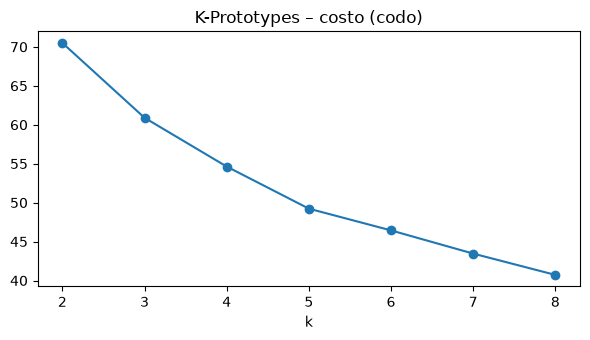

,modelo,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,ARI_sd,indice_combinado,candidato,costo
k,,,,,,,,,,,
2,K-Prototypes,0.203,0.292,0.361,0.034,62,0.978,0.031,0.198,False,70.502
3,K-Prototypes,0.173,0.270,0.354,0.035,36,0.755,0.165,0.131,True,60.894
4,K-Prototypes,0.166,0.250,0.354,0.035,19,0.789,0.144,0.131,True,54.629
5,K-Prototypes,0.153,0.238,0.346,0.024,25,0.656,0.134,0.100,True,49.226
6,K-Prototypes,0.202,0.214,0.348,0.041,12,0.597,0.091,0.121,True,46.434
7,K-Prototypes,0.142,0.224,0.342,0.035,15,0.600,0.106,0.085,True,43.456
8,K-Prototypes,0.164,0.207,0.344,0.040,8,0.683,0.095,0.112,False,40.722


In [7]:
cat_idx = [i for i, c in enumerate(VARS) if TIPOS[c] in ('cat', 'bin')]
Xk = X[VARS].copy()
for c in VARS:
    if TIPOS[c] in ('num', 'ord'):
        Xk[c] = (Xk[c] - Xk[c].min()) / (Xk[c].max() - Xk[c].min())
    else:
        Xk[c] = Xk[c].astype(str)
Xk_val = Xk.to_numpy(dtype=object)


def ajustar_kproto(Dm, k, idx):
    return KPrototypes(n_clusters=k, init='Cao', n_init=5, random_state=42).fit_predict(Xk_val[idx], categorical=cat_idx)


t_kp = tabla_k('K-Prototypes', ajustar_kproto, B=30)
t_kp['costo'] = [KPrototypes(n_clusters=k, init='Cao', n_init=5, random_state=42).fit(Xk_val, categorical=cat_idx).cost_ for k in K_RANGO]
plt.figure(figsize=(6, 3.5))
plt.plot(t_kp.index, t_kp['costo'], marker='o')
plt.title('K-Prototypes – costo (codo)')
plt.xlabel('k')
plt.tight_layout()
plt.show()
t_kp.round(3)

**Comentario 6:** K-Prototypes también mejora respecto de la v1 (siluetas de 0.14 a 0.20, ARI de 0.60 a 0.79), pero sigue por debajo de PAM. Su mejor candidato es k = 4 (silueta 0.166, ARI 0.79, índice 0.131).

# 7. Modelo 4 – HDBSCAN (densidad) sobre Gower

HDBSCAN no necesita fijar k: busca zonas densas y deja como **ruido (−1)** a las NNA que no pertenecen a ninguna. Se prueba una grilla de `min_cluster_size` (tamaño mínimo de grupo) y `min_samples` (qué tan conservador es al declarar ruido).

In [8]:
filas = []
for mcs in [5, 8, 10, 15]:
    for ms in [None, 3, 5]:
        lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms, metric='precomputed').fit(D.copy()).labels_
        k = len(set(lab) - {-1})
        ok = lab != -1
        sil = silhouette_score(D[np.ix_(ok, ok)], lab[ok], metric='precomputed') if k > 1 else np.nan
        filas.append({'min_cluster_size': mcs, 'min_samples': ms, 'clusters': k, 'ruido_n': int((~ok).sum()),
                      'ruido_pct': round((~ok).mean() * 100, 1), 'silueta_sin_ruido': sil,
                      'tamaños': np.bincount(lab[ok]).tolist() if k else []})
t_hdb = pd.DataFrame(filas)
t_hdb.round(3)

,min_cluster_size,min_samples,clusters,ruido_n,ruido_pct,silueta_sin_ruido,tamaños
0,5,NaN,7,81,50.3,0.538,"[27, 9, 6, 9, 5, 16, 8]"
1,5,3.0,10,77,47.8,0.518,"[10, 9, 16, 10, 9, 5, 8, 5, 6, 6]"
2,5,5.0,7,81,50.3,0.538,"[27, 9, 6, 9, 5, 16, 8]"
3,8,NaN,3,91,56.5,0.438,"[36, 25, 9]"
4,8,3.0,6,74,46.0,0.486,"[10, 9, 16, 10, 27, 15]"
5,8,5.0,5,80,49.7,0.482,"[16, 27, 14, 16, 8]"
6,10,NaN,2,112,69.6,0.486,"[29, 20]"
7,10,3.0,5,73,45.3,0.452,"[20, 16, 10, 27, 15]"
8,10,5.0,4,78,48.4,0.433,"[26, 16, 27, 14]"
9,15,NaN,0,161,100.0,NaN,[]


**Comentario 7:** HDBSCAN encuentra **núcleos densos más nítidos** que en la v1 (silueta sin ruido de hasta 0.54, por ejemplo un núcleo de 27 NNA), lo que confirma que, sin edad ni sexo, hay situaciones que se repiten de forma muy parecida. Aun así deja como ruido entre el **42 % y el 70 %** de las NNA, así que no sirve para asignar un perfil a cada residente. Se usa solo como diagnóstico.

# 8. Comparación de modelos y elección

In [9]:
modelos = {'AGNES promedio': (t_avg, ajustar_agnes('average')), 'AGNES completo': (t_com, ajustar_agnes('complete')),
           'PAM': (t_pam, ajustar_pam), 'K-Prototypes': (t_kp, ajustar_kproto)}
comp = []
for nombre, (t, f) in modelos.items():
    cand = t[t['candidato']]
    if len(cand):
        k = elegir_k(t)
        comp.append(t.loc[k].to_dict() | {'modelo': nombre, 'k_elegido': k})
    else:
        comp.append({'modelo': nombre, 'k_elegido': None})
comp = pd.DataFrame(comp).set_index('modelo')[['k_elegido', 'silueta', 'cohesion_intra', 'separacion_inter', 'dunn', 'tamano_min', 'ARI_medio', 'indice_combinado']]
comp.loc['HDBSCAN (mejor de la grilla)'] = [np.nan, t_hdb['silueta_sin_ruido'].max(), np.nan, np.nan, np.nan, np.nan, np.nan, np.nan]
comp.round(3)

,k_elegido,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,indice_combinado
modelo,,,,,,,,
AGNES promedio,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AGNES completo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PAM,6.0,0.282,0.197,0.353,0.036,13.0,0.770,0.217
K-Prototypes,4.0,0.166,0.250,0.354,0.035,19.0,0.789,0.131
HDBSCAN (mejor de la grilla),NaN,0.538,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
MEJOR = comp['indice_combinado'].idxmax()
K = int(comp.loc[MEJOR, 'k_elegido'])
lab = modelos[MEJOR][1](D, K, np.arange(N))
lab = pd.factorize(pd.Series(lab).map(lambda v: v), sort=True)[0]          # etiquetas 0..K-1
X['cluster'] = lab
print(f'Modelo elegido: {MEJOR} con k = {K}')
print('Tamaños:', X['cluster'].value_counts().sort_index().to_dict())
if MEJOR == 'PAM':
    medoides = X.index[pam(D, K)[0]].tolist()
    print('Medoides (NNA representativas):', medoides)

Modelo elegido: PAM con k = 6
Tamaños: {0: 29, 1: 30, 2: 13, 3: 44, 4: 22, 5: 23}
Medoides (NNA representativas): ['PPA_FN_0105', 'PPA_FN_0012', 'PPA_FN_0029', 'PPA_FN_0145', 'PPA_FN_0064', 'PPA_FN_0114']


**Comentario 8:** El modelo elegido para la v2 es **PAM con k = 6**: silueta 0.282, ARI 0.77, grupo mínimo de 13 NNA e índice combinado 0.217, frente a 0.131 de K-Prototypes. La silueta sigue en el rango de una estructura débil a moderada, pero es **39 % mayor que la de la v1** (0.203), y la estabilidad sigue alta.

# 9. Contraste con la versión 1

In [11]:
# ¿Cuánto se parece la partición v2 a la v1? ¿Cuánto pesan edad y sexo en los grupos de cada versión?
ruta_v1 = RUTA / 'Clusters_v1.xlsx'
if ruta_v1.exists():
    v1 = pd.read_excel(ruta_v1, sheet_name='asignacion').set_index('id_persona')['cluster']
    print(f'ARI entre la partición v1 y la v2: {adjusted_rand_score(v1.loc[X.index], X["cluster"]):.3f}')
    print('Tabla cruzada (filas = cluster v1, columnas = cluster v2):')
    print(pd.crosstab(v1.loc[X.index], X['cluster']))
    for nombre, labv in [('v1', v1.loc[X.index]), ('v2', X['cluster'])]:
        print(f"{nombre}: V de Cramér cluster-sexo = {cramer_v(labv, X['sexo']):.3f} | η cluster-edad = {np.sqrt(eta2(labv, X['edad_anios'])):.3f} | "
              f"V de Cramér cluster-hogar = {cramer_v(labv, X['hogar']):.3f}")
else:
    print('Ejecute primero el notebook de la versión 1.')

ARI entre la partición v1 y la v2: 0.423
Tabla cruzada (filas = cluster v1, columnas = cluster v2):
cluster   0   1   2   3   4   5
cluster                        
0         1   3   0  32   0   0
1         0  18   0   8   0   0
2        16   0  10   3   0   5
3         0   3   3   1  21   0
4        12   6   0   0   1  18
v1: V de Cramér cluster-sexo = 0.610 | η cluster-edad = 0.468 | V de Cramér cluster-hogar = 0.395
v2: V de Cramér cluster-sexo = 0.160 | η cluster-edad = 0.382 | V de Cramér cluster-hogar = 0.304


**Comentario 9:** La v2 **reorganiza** a los grupos de la v1 (ARI 0.42) y deja de depender del sexo: la asociación con el sexo baja de **0.61 a 0.16**, con el hogar de 0.40 a 0.30 y con la edad de 0.47 a 0.38. La tabla cruzada muestra cómo:
- El cluster 0 de la v1 (varones con PTI vigente y malnutrición) y parte del 1 (mujeres con PTI vigente) se juntan en el **cluster 3 de la v2** (PTI vigente con alerta nutricional, de ambos sexos).
- El cluster 4 de la v1 (varones con PTI vencido) se reparte entre el **0** (sin PTI vigente y con malnutrición) y el **5** (sin PTI vigente y sin alerta nutricional), según su nutrición.
- El cluster 2 de la v1 (mujeres sin PTI) se divide entre el **0**, el **2** (casos de salud crónica y muy larga permanencia) y el **5**.
- El grupo de medida firme se conserva (cluster 3 de la v1 → cluster 4 de la v2, 21 de 28).

Es decir, los perfiles de la v2 se forman por la **situación** de la NNA y no por quién es.

# 10. Diagnóstico: ¿alguna variable impide una mejor agrupación?

Se retira cada variable de a una, se recalcula Gower y se vuelve a ajustar el modelo elegido en los k candidatos. Retirar una variable casi siempre sube un poco la silueta, porque hay menos dimensiones. Por eso solo se considera que una variable **perjudica** la agrupación si su retiro mejora la silueta de forma **consistente en todos los k** y en una magnitud apreciable (> 0.03 en promedio).

In [12]:
base_sil = {k: silhouette_score(D, modelos[MEJOR][1](D, k, np.arange(N)), metric='precomputed') for k in K_CANDIDATOS}
loo = {}
for v in VARS:
    Dv = gower(X, {c: t for c, t in TIPOS.items() if c != v})
    loo[v] = {k: silhouette_score(Dv, modelos[MEJOR][1](Dv, k, np.arange(N)), metric='precomputed') - base_sil[k] for k in K_CANDIDATOS}
loo = pd.DataFrame(loo).T
loo.columns = [f'Δsil k={k}' for k in K_CANDIDATOS]
loo['Δ promedio'] = loo.mean(axis=1)
loo['mejora en todos los k'] = (loo.iloc[:, :len(K_CANDIDATOS)] > 0).all(axis=1)
loo.sort_values('Δ promedio', ascending=False).round(3)

,Δsil k=3,Δsil k=4,Δsil k=5,Δsil k=6,Δsil k=7,Δ promedio,mejora en todos los k
nivel_atencion_salud_mental,0.027,0.029,0.036,0.061,0.089,0.048,True
estado_pti,0.077,0.035,0.014,0.004,0.011,0.028,True
prop_meses_sin_pti_vigente,0.065,0.016,0.030,-0.002,0.026,0.027,False
salud_fisica_cronica,0.012,0.021,0.020,0.039,0.022,0.023,True
ln_permanencia,0.018,-0.000,0.013,0.040,0.019,0.018,False
procedencia_provincias,0.012,0.010,0.018,0.020,0.024,0.017,True
score_imc,0.015,0.004,0.029,0.000,0.029,0.015,True
flag_rezago_escolar,0.008,0.016,0.018,0.016,0.015,0.014,True
presenta_discapacidad,0.010,0.008,0.011,0.017,0.015,0.012,True
malnutricion_flag,0.072,0.065,-0.033,-0.045,-0.033,0.005,False


**Comentario 10:** Solo **`nivel_atencion_salud_mental`** cumple el criterio: retirarla mejora la silueta en todos los k, con una media de +0.048 (+0.06 con k = 6). La intensidad de la atención psicológica es casi **independiente** de la situación legal, del PTI y de la nutrición (η = 0.30 con los clusters), así que "corta" a los grupos en lugar de reforzarlos. **No se excluye**, porque es la única variable del área psicoemocional, una de las dimensiones obligatorias del objetivo. Sin ella, los perfiles no dirían nada sobre el soporte que recibe cada grupo. Queda registrado como alternativa evaluada: un modelo sin esta variable separaría algo mejor, pero el nivel de atención tendría que agregarse después para describir cada grupo. Las demás variables mejoran menos de 0.03 en promedio o no lo hacen de forma consistente.

# 11. Sensibilidad: NNA recuperados (INC-01 / INC-06)

En el Paso 4B se recuperaron 16 NNA con correcciones que la institución todavía tiene en revisión. Se ajusta el modelo **sin ellos** y se compara la asignación de las 145 NNA restantes con la del modelo completo.

In [13]:
sin_rec = np.asarray(X['id_recuperado'] == 'No')
lab_sin = modelos[MEJOR][1](D[np.ix_(sin_rec, sin_rec)], K, np.where(sin_rec)[0])
ari_rec = adjusted_rand_score(X.loc[sin_rec, 'cluster'], lab_sin)
print(f'ARI entre el modelo completo y el modelo sin los 16 NNA recuperados (sobre las {sin_rec.sum()} NNA comunes): {ari_rec:.3f}')
print('Distribución de los recuperados por cluster:', X.loc[~sin_rec, 'cluster'].value_counts().sort_index().to_dict())

ARI entre el modelo completo y el modelo sin los 16 NNA recuperados (sobre las 145 NNA comunes): 1.000
Distribución de los recuperados por cluster: {0: 1, 1: 3, 2: 1, 3: 5, 4: 2, 5: 4}


**Comentario 11:** Igual que en la v1, al excluir a los 16 NNA recuperados las 145 restantes quedan **exactamente en los mismos grupos (ARI = 1.00)**. Los recuperados se reparten en los 6 grupos (1, 3, 1, 5, 2 y 4), así que su inclusión no sesga los perfiles.

# 12. Caracterización de los perfiles

In [14]:
DESCRIPTIVAS = ['edad_anios', 'sexo', 'nivel_educativo', 'hogar', 'provisional_prolongada', 'activo_al_corte', 'permanencia_cat', 'tipo_discapacidad']
imp = {}
for v in VARS + [c for c in DESCRIPTIVAS if c not in VARS]:
    es_num = TIPOS.get(v) in ('num', 'ord') or (v not in TIPOS and pd.api.types.is_numeric_dtype(X[v]) and X[v].nunique() > 2)
    imp[v] = {'asociación con el cluster': np.sqrt(eta2(X['cluster'], X[v])) if es_num else cramer_v(X['cluster'], X[v]),
              'medida': 'η' if es_num else 'V de Cramér', 'uso': 'modelo' if v in VARS else 'descriptiva'}
imp = pd.DataFrame(imp).T.sort_values('asociación con el cluster', ascending=False)
imp

,asociación con el cluster,medida,uso
malnutricion_flag,0.895498,V de Cramér,modelo
prop_meses_sin_pti_vigente,0.755134,η,modelo
score_imc,0.624363,η,modelo
estado_pti,0.614301,V de Cramér,modelo
provisional_prolongada,0.610834,V de Cramér,descriptiva
salud_fisica_cronica,0.560137,V de Cramér,modelo
situacion_juridica,0.514459,V de Cramér,modelo
ln_permanencia,0.432019,η,modelo
edad_anios,0.381664,η,descriptiva
hogar,0.303765,V de Cramér,descriptiva


In [15]:
num_desc = ['edad_anios', 'meses_permanencia', 'nivel_atencion_salud_mental', 'score_imc', 'prop_meses_sin_pti_vigente']
perfil = X.groupby('cluster').agg(n=('cluster', 'size'), **{f'{c} (mediana)': (c, 'median') for c in num_desc})
perfil['% del total'] = (perfil['n'] / N * 100).round(1)
binarias = ['procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'flag_rezago_escolar', 'malnutricion_flag',
            'provisional_prolongada', 'activo_al_corte']
pct = X.assign(mujer=(X['sexo'] == 'F').astype(int)).groupby('cluster')[['mujer'] + binarias].mean().mul(100).round(0)
pct.columns = [f'% {c}' for c in pct.columns]
pd.concat([perfil.round(2), pct], axis=1).T

cluster,0,1,2,3,4,5
n,29.00,30.00,13.00,44.00,22.00,23.00
edad_anios (mediana),9.52,9.57,14.66,8.60,13.24,7.48
meses_permanencia (mediana),40.80,62.90,150.40,41.15,115.50,39.00
nivel_atencion_salud_mental (mediana),2.00,2.00,3.00,2.00,1.00,2.00
score_imc (mediana),2.00,0.00,2.00,2.00,0.00,0.00
prop_meses_sin_pti_vigente (mediana),1.00,0.00,1.00,0.15,0.90,1.00
% del total,18.00,18.60,8.10,27.30,13.70,14.30
% mujer,48.00,53.00,62.00,39.00,36.00,39.00
% procedencia_provincias,17.00,20.00,8.00,7.00,0.00,9.00
% salud_fisica_cronica,7.00,10.00,77.00,7.00,23.00,0.00


In [16]:
for c in ['situacion_juridica', 'estado_pti', 'nivel_educativo', 'edad_cat', 'hogar']:
    print(f'\n{c} (% dentro de cada cluster)')
    print((pd.crosstab(X['cluster'], X[c], normalize='index') * 100).round(0).to_string())


situacion_juridica (% dentro de cada cluster)
situacion_juridica  1 Tutela / Medida judicial firme  2 Acogimiento residencial formal  3 Investigacion tutelar / Medida provisional  4 Sin definir / En observacion
cluster                                                                                                                                                             
0                                                0.0                               3.0                                          97.0                             0.0
1                                                3.0                               3.0                                          93.0                             0.0
2                                               54.0                               8.0                                          31.0                             8.0
3                                                7.0                               9.0                                          

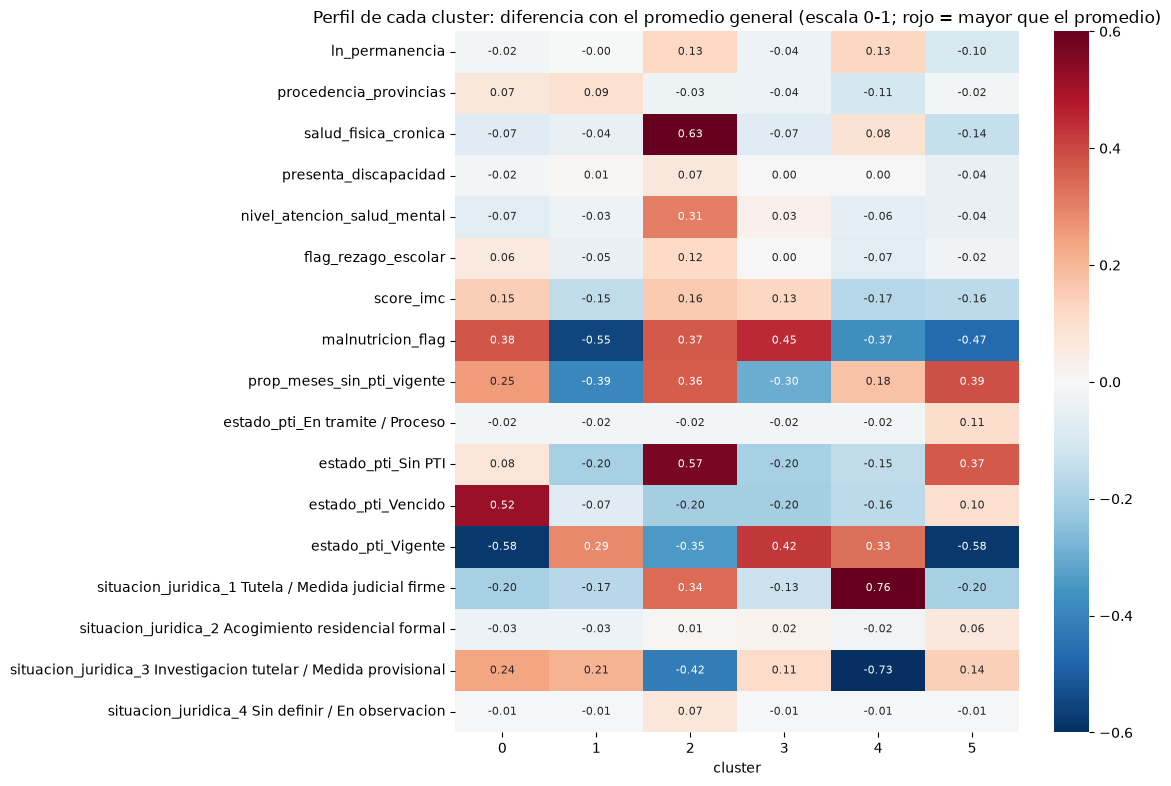

In [17]:
# Mapa de calor: diferencia de cada cluster respecto del total (variables del modelo, codificadas)
enc = pd.get_dummies(X[VARS].astype({c: str for c in VARS if TIPOS[c] == 'cat'}), dtype=float)
enc = (enc - enc.min()) / (enc.max() - enc.min())
dif = enc.groupby(X['cluster']).mean() - enc.mean()
plt.figure(figsize=(1.3 * K + 4, 0.38 * dif.shape[1] + 1.5))
sns.heatmap(dif.T, cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6, annot=True, fmt='.2f', annot_kws={'size': 8})
plt.title('Perfil de cada cluster: diferencia con el promedio general (escala 0-1; rojo = mayor que el promedio)')
plt.xlabel('cluster')
plt.tight_layout()
plt.show()

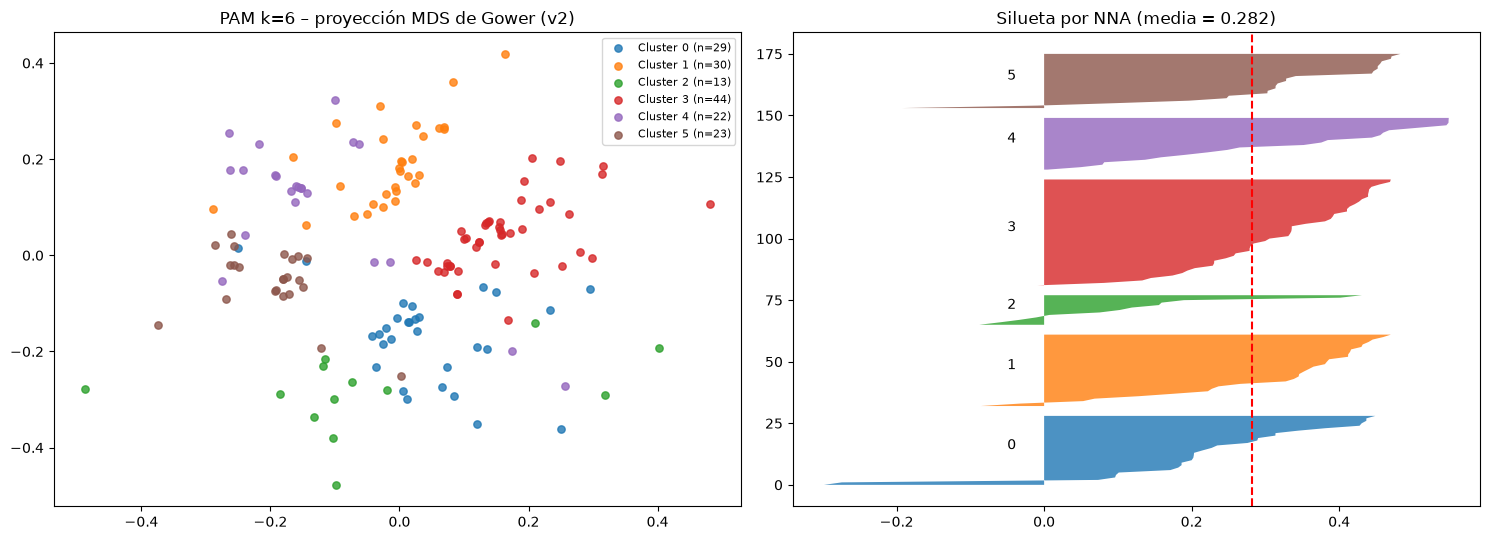

Silueta media por cluster: {0: 0.22, 1: 0.306, 2: 0.111, 3: 0.318, 4: 0.321, 5: 0.316}


In [18]:
coords = MDS(n_components=2, dissimilarity='precomputed', random_state=42, n_init=4).fit_transform(D)
sil_i = silhouette_samples(D, X['cluster'], metric='precomputed')
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for c in range(K):
    m = (X['cluster'] == c).values
    ax[0].scatter(coords[m, 0], coords[m, 1], s=28, alpha=.8, label=f'Cluster {c} (n={m.sum()})')
ax[0].set_title(f'{MEJOR} k={K} – proyección MDS de Gower ({VERSION})')
ax[0].legend(fontsize=8)
y0 = 0
for c in range(K):
    s = np.sort(sil_i[X['cluster'] == c])
    ax[1].fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, alpha=.8)
    ax[1].text(-0.05, y0 + len(s) / 2, str(c))
    y0 += len(s) + 3
ax[1].axvline(sil_i.mean(), color='red', ls='--')
ax[1].set_title(f'Silueta por NNA (media = {sil_i.mean():.3f})')
plt.tight_layout()
plt.show()
print('Silueta media por cluster:', pd.Series(sil_i).groupby(X['cluster'].values).mean().round(3).to_dict())

**Comentario 12 – perfiles.** Las variables que más distinguen a los perfiles son la **malnutrición** (V = 0.90), el **historial del PTI** (η = 0.76), el score de IMC (η = 0.62), el **estado del PTI** (V = 0.61), la **provisional prolongada** (V = 0.61, que no entró al modelo y aun así queda bien separada) y la salud física crónica (V = 0.56). El sexo prácticamente no participa (V = 0.16).

| Perfil | n (%) | Situación legal | PTI | Nutrición y salud | Otros rasgos |
|---|---|---|---|---|---|
| **0 – Provisional prolongada, sin PTI vigente y con malnutrición** | 29 (18 %) | Provisional 97 % (prolongada 97 %) | **Vencido 72 %, sin PTI 28 %** | **Malnutrición 93 %** | 9.5 años, 3.4 años en el CAR, rezago 17 % |
| **1 – Provisional prolongada con PTI vigente, sin alerta nutricional** | 30 (19 %) | Provisional 93 % (prolongada 80 %) | **Vigente 87 %** | Sin malnutrición (0 %) | 5.2 años en el CAR, procedencia de provincias 20 % |
| **2 – Muy larga permanencia con salud crónica, malnutrición y sin PTI** | 13 (8 %) | Firme 54 %, provisional 31 % | **Sin PTI 77 %** | **Salud crónica 77 %**, malnutrición 92 %, discapacidad 15 % | **14.7 años, 12.5 años en el CAR**, rezago 23 %; 54 % de Miguel Echenique |
| **3 – PTI vigente con alerta nutricional** | 44 (27 %) | Provisional 84 % | **Vigente 100 %** | **Malnutrición 100 %** (mediana = sobrepeso) | 8.6 años, 3.4 años en el CAR |
| **4 – Adolescentes con medida firme y larga permanencia** | 22 (14 %) | **Firme 95 %** | Vigente 91 % (regularizado recién: sin vigente en 90 % de su historial) | Sin alerta (18 %), salud crónica 23 % | 13.2 años, 9.6 años en el CAR, **único perfil cuya mediana de atención psicológica es 1 (sin atención)**; 55 % de Matogroso hombres |
| **5 – Niñez sin PTI vigente y sin alerta nutricional** | 23 (14 %) | Provisional 87 %, urgencia 13 % | **Sin PTI 57 %, vencido 30 %, en trámite 13 %** | Sin alerta (9 %) | **7.5 años**, 3.2 años en el CAR; **39 % egresó durante el periodo** |

El perfil 2 es el menos cohesionado (silueta 0.11): reúne casos complejos y heterogéneos que conviene revisar uno por uno. Los perfiles 1, 3, 4 y 5 son los más nítidos (silueta de 0.31 a 0.32).

# 13. Guardado

In [19]:
salida = X[['id_original', 'cluster'] + VARS + [c for c in DESCRIPTIVAS if c not in VARS]].copy()
salida['silueta_individual'] = sil_i.round(3)
resumen_modelos = pd.concat([t_avg, t_com, t_pam, t_kp])
with pd.ExcelWriter(RUTA / f'Clusters_{VERSION}.xlsx') as w:
    salida.reset_index().to_excel(w, sheet_name='asignacion', index=False)
    resumen_modelos.reset_index().to_excel(w, sheet_name='metricas_por_k', index=False)
    comp.reset_index().to_excel(w, sheet_name='comparacion_modelos', index=False)
    t_hdb.to_excel(w, sheet_name='hdbscan', index=False)
    loo.reset_index().to_excel(w, sheet_name='diagnostico_variables', index=False)
    imp.reset_index().to_excel(w, sheet_name='importancia', index=False)
print('Guardado:', (RUTA / f'Clusters_{VERSION}.xlsx').relative_to(BASE))

Guardado: Resultados_EnfoqueB\Clusters_v2.xlsx


**Comentario 13:** La asignación de la v2 y sus métricas se guardan en `Resultados_EnfoqueB/Clusters_v2.xlsx`. **Resumen de la v2:** PAM con k = 6 da los perfiles mejor separados (silueta 0.28) y estables (ARI 0.77), y se definen por la situación legal, el PTI y la nutrición, que son las dimensiones que el equipo técnico puede intervenir. La comparación final con la v1 y la v3 está en el notebook de la v3.